# When a near-zero loss is wrong: Deep Galerkin with non-smooth terminal conditions

Part of ACT496 (Deep Learning for Stochastic Control, University of Toronto, Fall 2026), supervised by Prof. Sebastian Jaimungal. Excerpt of the 1 Nov 2026 notebook (Part 1 only).

**Problem.** Learn $g$ solving the backward heat equation
$$\partial_t g+\tfrac12\partial_{xx}g=0,\qquad g(T,x)=H(x),$$
with a Deep Galerkin network that imposes the terminal condition exactly,
$$g_\theta(t,x)=H(x)+(T-t)\,N_\theta(t,x),$$
and is trained on the mean squared PDE residual at random points $(t_i,x_i)$. By Feynman–Kac, $g(t,x)=\mathbb E[H(x+\sqrt{T-t}\,Z)]$, so every case below has an exact solution to check against.

**Finding.** For a non-smooth $H$ (an indicator, or $(1-x)_+$), training converges to a loss of about $10^{-7}$ while the error against the exact solution stays at $0.4$–$0.5$. Gaussian smoothing of $H$ fixes this and still keeps an exact solution.

In [1]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import time

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.set_default_dtype(torch.float32)

T = 1.0
x_max = 5.0 * np.sqrt(T)
batch_size = 1024
n_iter_heat = 4000
learning_rate = 1e-3

normal_dist = torch.distributions.Normal(loc=0.0, scale=1.0)
Phi = normal_dist.cdf
phi = lambda z: torch.exp(normal_dist.log_prob(z))

## Exact solutions (Feynman–Kac)

- $H(x)=\sin x$: $\ g(t,x)=e^{-(T-t)/2}\sin x$.
- $H(x)=\mathbf 1\{x>0\}$: $\ g(t,x)=\Phi\big(x/\sqrt{T-t}\big)$.
- $H(x)=(1-x)_+$: $\ g(t,x)=(1-x)\,\Phi(d)+\sqrt{\tau}\,\phi(d)$, with $\tau=T-t$, $d=(1-x)/\sqrt\tau$.

## Network and training

$N_\theta$: 3 hidden layers of 64 tanh units. Loss $=\frac1N\sum_i\big(\partial_tg_\theta+\tfrac12\partial_{xx}g_\theta\big)^2(t_i,x_i)$ with $t_i\sim U[0,T]$, $x_i\sim U[-5,5]$; derivatives by autograd.

In [2]:
class FeedForwardNN(nn.Module):
    def __init__(self, hidden_dim=64, n_hidden=3):
        super().__init__()
        layers = [nn.Linear(2, hidden_dim), nn.Tanh()]
        for _ in range(n_hidden - 1):
            layers += [nn.Linear(hidden_dim, hidden_dim), nn.Tanh()]
        layers += [nn.Linear(hidden_dim, 1)]
        self.net = nn.Sequential(*layers)

    def forward(self, t, x):
        return self.net(torch.cat([t, x], dim=1))

class HeatPINN(nn.Module):
    """g_theta(t, x) = H(x) + (T - t) N_theta(t, x): terminal condition holds exactly."""
    def __init__(self, H):
        super().__init__()
        self.H = H
        self.nn = FeedForwardNN()

    def forward(self, t, x):
        return self.H(x) + (T - t) * self.nn(t, x)

def generator(fn, t, x):
    """Returns f, x, and the PDE residual (d_t + 1/2 d_xx) f at the sampled points."""
    t = t.detach().requires_grad_(True)
    x = x.detach().requires_grad_(True)
    f = fn(t, x)
    ones = torch.ones_like(f)
    f_t  = torch.autograd.grad(f, t, grad_outputs=ones, create_graph=True)[0]
    f_x  = torch.autograd.grad(f, x, grad_outputs=ones, create_graph=True)[0]
    f_xx = torch.autograd.grad(f_x, x, grad_outputs=torch.ones_like(f_x), create_graph=True)[0]
    return f, x, f_t + 0.5 * f_xx

def sample(n):
    t = T * torch.rand(n, 1, device=device)
    x = (2 * torch.rand(n, 1, device=device) - 1) * x_max
    return t, x

def train_heat(H, n_iter=n_iter_heat, seed=1234):
    torch.manual_seed(seed)
    model = HeatPINN(H).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=learning_rate)
    sched = torch.optim.lr_scheduler.StepLR(opt, step_size=max(1, n_iter // 3), gamma=0.3)
    hist = []
    for step in range(n_iter):
        t, x = sample(batch_size)
        _, _, res = generator(model, t, x)
        loss = torch.mean(res ** 2)
        opt.zero_grad(); loss.backward(); opt.step(); sched.step()
        hist.append(loss.item())
    return model, hist

x_grid = torch.linspace(-x_max, x_max, 401, device=device).reshape(-1, 1)
mask = (x_grid.abs() <= 3).cpu().numpy().ravel()
t_plot = [0.0, 0.5 * T, 0.9 * T]

def eval_on_grid(fn, t_value):
    tg = torch.full_like(x_grid, t_value)
    with torch.no_grad():
        return fn(tg, x_grid).cpu().numpy().ravel()

def max_err(fn, ref):
    return [np.abs(eval_on_grid(fn, tv) - eval_on_grid(ref, tv))[mask].max() for tv in t_plot]

## 1. The failure: non-smooth payoffs

In [3]:
def H_ind_raw(x): return (x > 0).float()
def H_put_raw(x): return torch.clamp(1.0 - x, min=0.0)
def g_exact_ind_raw(t, x): return Phi(x / torch.sqrt(T - t))
def g_exact_put_raw(t, x):
    tau = T - t; d = (1.0 - x) / torch.sqrt(tau)
    return (1.0 - x) * Phi(d) + torch.sqrt(tau) * phi(d)

for name, H, g_ex in [("indicator", H_ind_raw, g_exact_ind_raw), ("put", H_put_raw, g_exact_put_raw)]:
    m, hist = train_heat(H, n_iter=1500)
    nn_size = np.abs(eval_on_grid(lambda t, x: m.nn(t, x), 0.0)).max()
    print(f"{name:10s} final loss {np.mean(hist[-100:]):.1e} | max|N_theta| {nn_size:.3f} | "
          f"max err vs exact at t=0,0.5,0.9: " + ", ".join(f"{e:.3f}" for e in max_err(m, g_ex)))

indicator  final loss 2.1e-07 | max|N_theta| 0.000 | max err vs exact at t=0,0.5,0.9: 0.500, 0.500, 0.500


put        final loss 2.1e-07 | max|N_theta| 0.000 | max err vs exact at t=0,0.5,0.9: 0.399, 0.282, 0.126


**The loss is essentially zero, yet the error is large** ($0.5$ for the indicator, $\approx\phi(0)=0.399$ for the put at $t=0$, $x=1$). The network has learned $N_\theta\approx0$, i.e. $g_\theta\approx H$.

**Why.** Autograd differentiates $H$ pointwise. For $H(x)=(1-x)_+$, $H''(x)=0$ for every $x\ne1$; for $H=\mathbf 1\{x>0\}$, $H'=H''=0$ for every $x\ne0$. The curvature sits in a Dirac mass at the kink or jump, which a randomly sampled point hits with probability $0$. So for $N_\theta\equiv0$ the residual $\tfrac12H''(x)$ is $0$ at every sampled point: the trivial network is an exact minimiser of the *sampled* loss, although $g_\theta=H$ does not solve the PDE.

## 2. The fix: Gaussian-smoothed payoff

Replace $H$ by $H_\delta(x)=\mathbb E[H(x+\delta Z)]$. Since $\sqrt\tau Z+\delta Z'\sim N(0,\tau+\delta^2)$ for independent $Z,Z'$, the exact solution for $H_\delta$ is the old formula with $\tau$ replaced by $\tau+\delta^2$. We use $\delta=0.1$.

sin         22.8s | final PDE loss 6.4e-05 | max err on [-3,3] at t=0,0.5,0.9: 0.0013, 0.0010, 0.0002


indicator   24.2s | final PDE loss 2.8e-02 | max err on [-3,3] at t=0,0.5,0.9: 0.0055, 0.0063, 0.0152


put         25.7s | final PDE loss 6.5e-04 | max err on [-3,3] at t=0,0.5,0.9: 0.0030, 0.0027, 0.0076


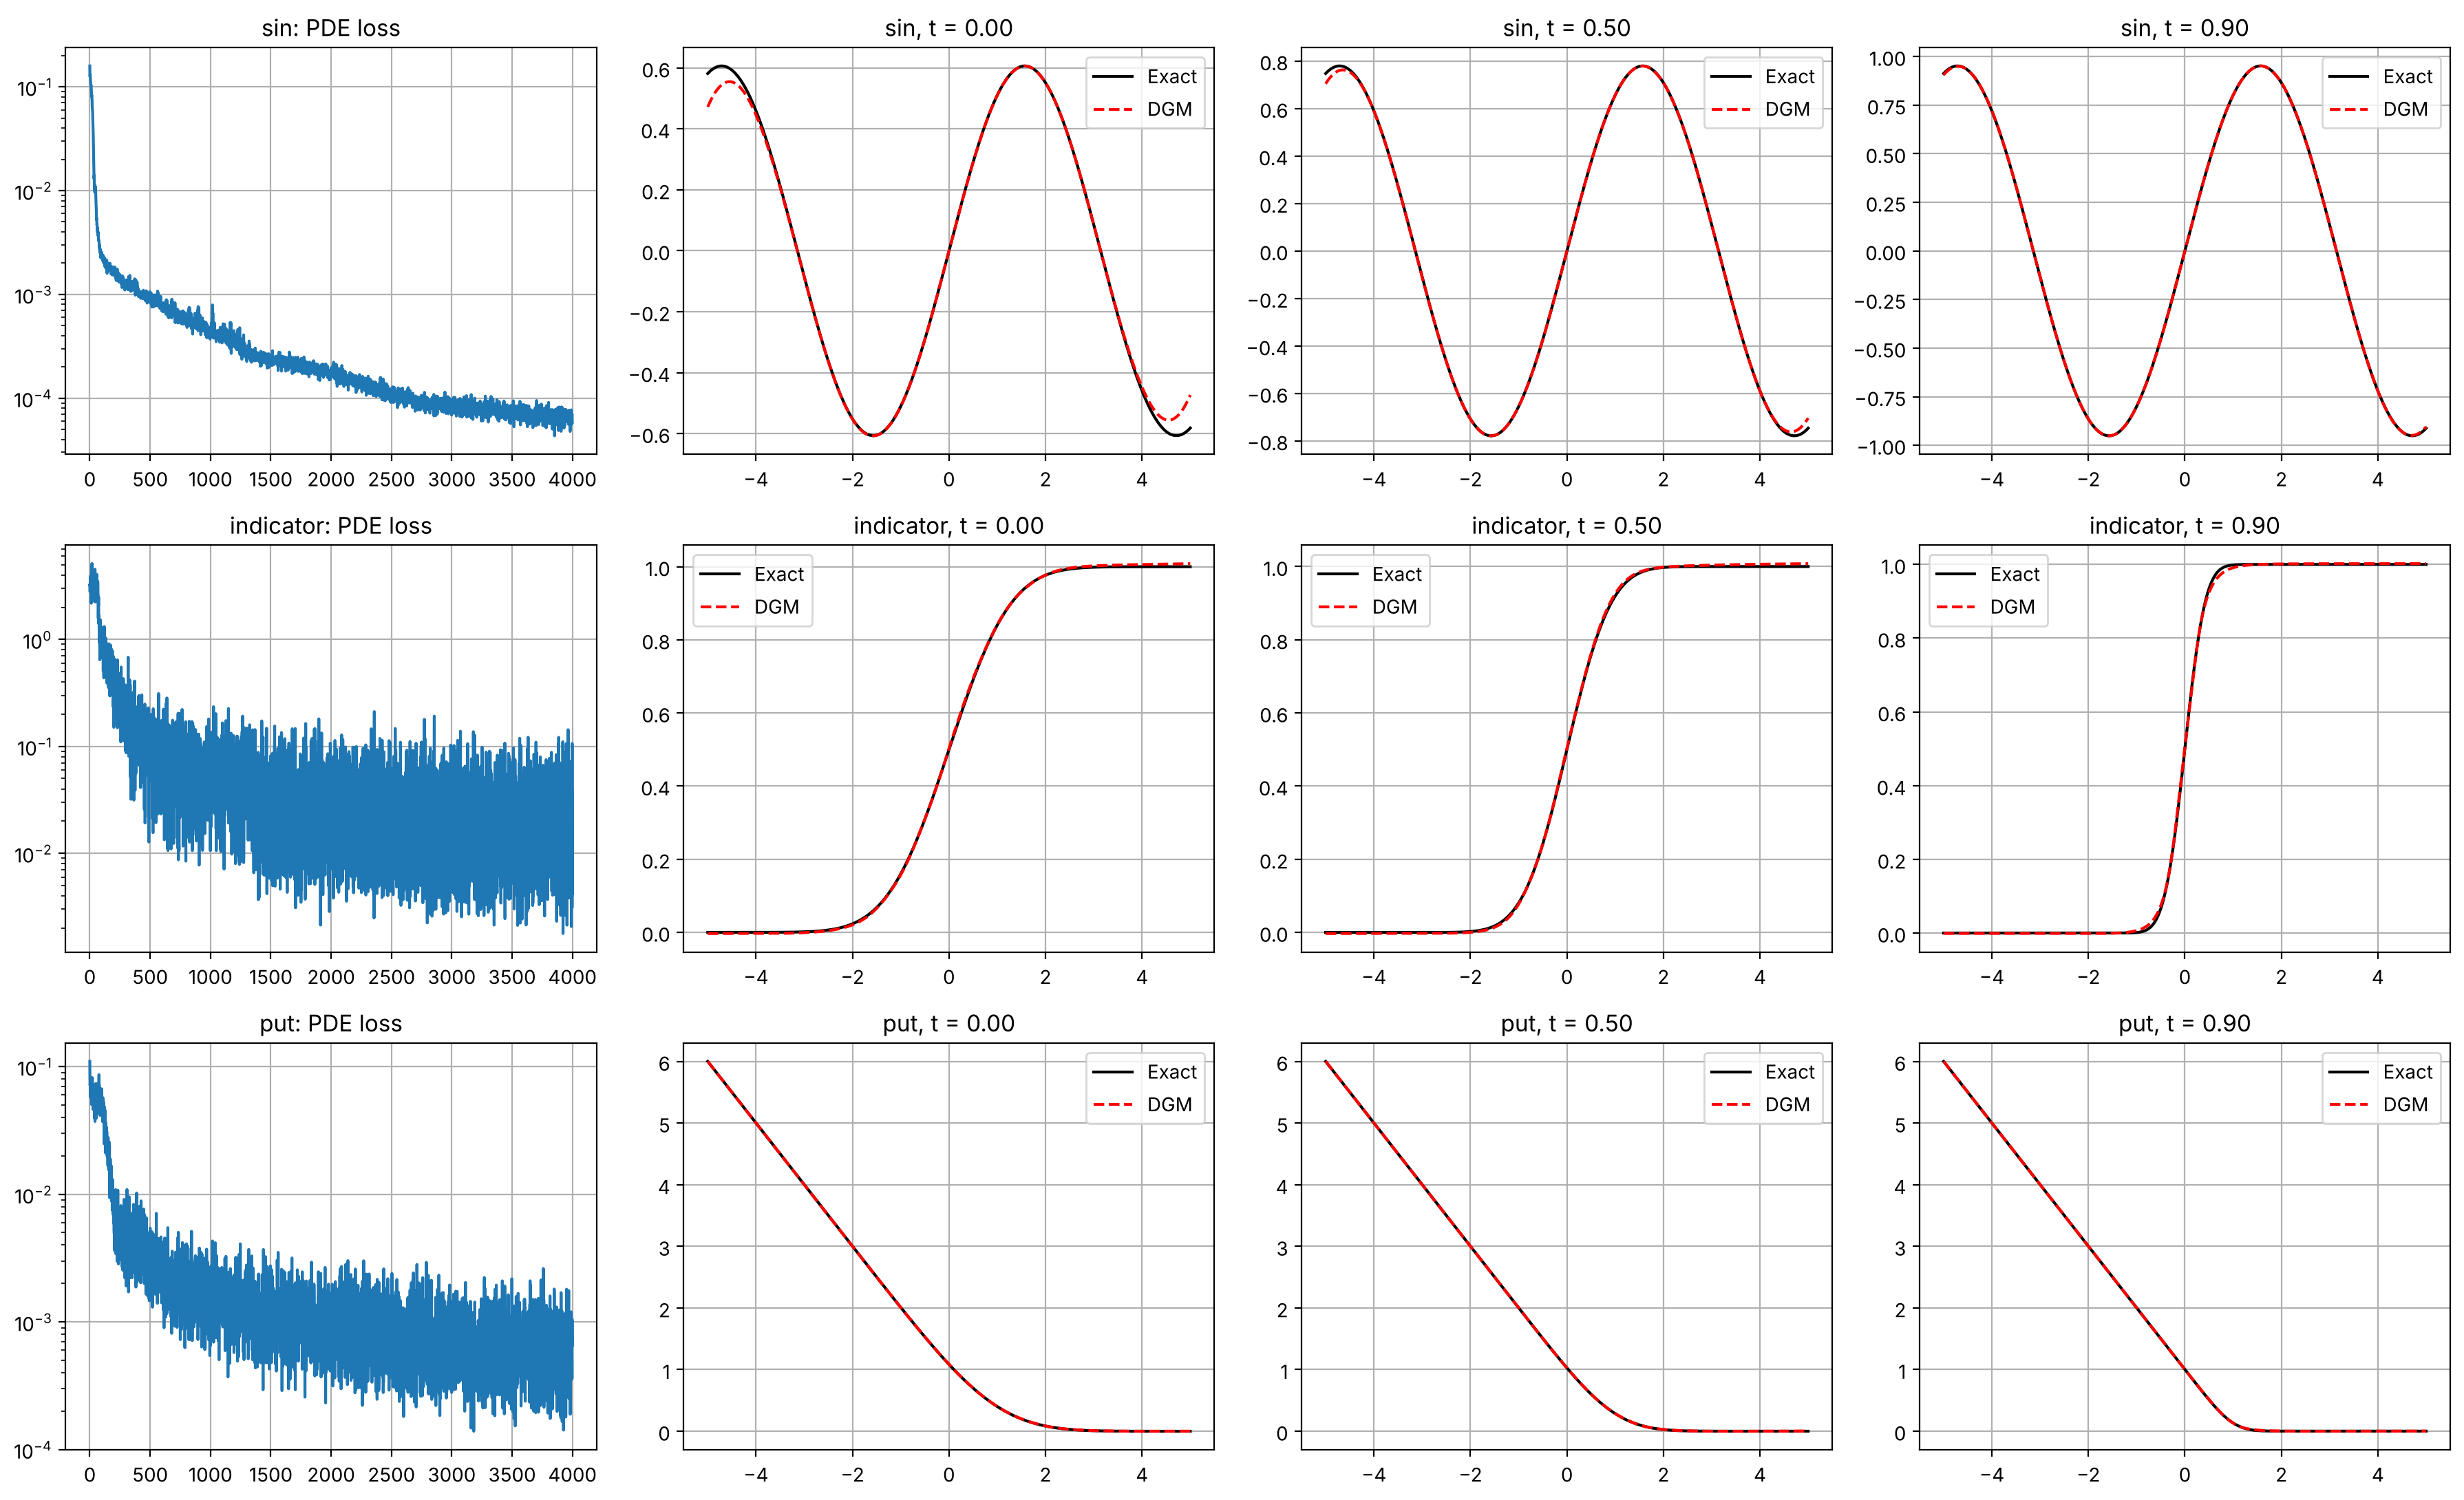

In [4]:
delta = 0.1

def g_ind(t, x, extra=delta**2):  return Phi(x / torch.sqrt(T - t + extra))
def g_put(t, x, extra=delta**2):
    s = torch.sqrt(T - t + extra); d = (1.0 - x) / s
    return (1.0 - x) * Phi(d) + s * phi(d)

def H_sin(x): return torch.sin(x)
def H_ind(x): return g_ind(torch.full_like(x, T), x)     # = Phi(x / delta)
def H_put(x): return g_put(torch.full_like(x, T), x)     # smoothed (1 - x)_+
def g_exact_sin(t, x): return torch.exp(-0.5 * (T - t)) * torch.sin(x)

PAYOFFS = {"sin": (H_sin, g_exact_sin), "indicator": (H_ind, g_ind), "put": (H_put, g_put)}

g_models, heat_hist = {}, {}
for name, (H, g_ex) in PAYOFFS.items():
    t0 = time.time()
    g_models[name], heat_hist[name] = train_heat(H)
    print(f"{name:10s} {time.time()-t0:5.1f}s | final PDE loss {np.mean(heat_hist[name][-100:]):.1e} | "
          "max err on [-3,3] at t=0,0.5,0.9: " + ", ".join(f"{e:.4f}" for e in max_err(g_models[name], g_ex)))

fig, axes = plt.subplots(3, 4, figsize=(18, 11))
for r, (name, (H, g_ex)) in enumerate(PAYOFFS.items()):
    axes[r, 0].semilogy(heat_hist[name]); axes[r, 0].set_title(f"{name}: PDE loss"); axes[r, 0].grid(True)
    for c, tv in enumerate(t_plot):
        ax = axes[r, c + 1]
        ax.plot(x_grid.cpu(), eval_on_grid(g_ex, tv), "k-", label="Exact")
        ax.plot(x_grid.cpu(), eval_on_grid(g_models[name], tv), "r--", label="DGM")
        ax.set_title(f"{name}, t = {tv:.2f}"); ax.grid(True); ax.legend()
plt.tight_layout(); plt.savefig("../figures/01_smoothing_fix.png", dpi=110); plt.show()

## Summary

- With the hard terminal constraint $g_\theta=H+(T-t)N_\theta$ and a non-smooth $H$, the trivial network has zero sampled residual. Training reaches a loss of about $10^{-7}$ with an error of $0.4$–$0.5$: **a small loss does not mean a correct solution.**
- Gaussian smoothing of the payoff removes the problem, keeps a closed-form solution ($\tau\to\tau+\delta^2$), and brings the error down to about $0.015$ or less. The final loss is larger than before, but the error is 30 to 100 times smaller.